In [1]:
from datasets import load_dataset
from transformers import AutoTokenizer, BertModel
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
import torch.nn.functional as F

d:\anaconda3\envs\CS2109S\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
sst2_dataset = load_dataset("SetFit/sst2")

Repo card metadata block was not found. Setting CardData to empty.


In [3]:
model = BertModel.from_pretrained("bert-base-uncased")

In [4]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
print(sst2_dataset)
print(sst2_dataset['train'])
print(sst2_dataset['train'][0])
print(sst2_dataset['train']['text'])


DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 6920
    })
    validation: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 872
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 1821
    })
})
Dataset({
    features: ['text', 'label', 'label_text'],
    num_rows: 6920
})
{'text': 'a stirring , funny and finally transporting re-imagining of beauty and the beast and 1930s horror films', 'label': 1, 'label_text': 'positive'}
['a stirring , funny and finally transporting re-imagining of beauty and the beast and 1930s horror films', 'apparently reassembled from the cutting-room floor of any given daytime soap .', "they presume their audience wo n't sit still for a sociology lesson , however entertainingly presented , so they trot out the conventional science-fiction elements of bug-eyed monsters and futuristic women in skimpy clothes .", 'this is a visually st

In [5]:
train_text_lengths = [len(tokenizer.tokenize(text)) for text in sst2_dataset['train']['text']]

validation_text_lengths = [len(tokenizer.tokenize(text)) for text in sst2_dataset['validation']['text']]

max_train_length = max(train_text_lengths)
max_validation_length = max(validation_text_lengths)

In [6]:

import pathlib
EMBEDDING_TRAIN_SST2 = "../data/sst-2/embedding_train.pt"
EMBEDDING_VALIDATION_SST2 = "../data/sst-2/embedding_validation.pt"
train_texts = sst2_dataset['train']['text'][:500]
validation_texts = sst2_dataset['validation']['text'][:80]
sst2_train_embeddings = []
sst2_validation_embeddings = []
if pathlib.Path(EMBEDDING_TRAIN_SST2).is_file() and pathlib.Path(EMBEDDING_VALIDATION_SST2).is_file():
    print("Loading embeddings")
    sst2_train_embeddings = torch.load(EMBEDDING_TRAIN_SST2)
    sst2_validation_embeddings = torch.load(EMBEDDING_VALIDATION_SST2)
    
else:
    for text in tqdm(train_texts, desc="Embedding train SST2", total=len(train_texts)):
        tokenized_text = tokenizer(text, truncation=True, max_length=max_train_length, return_tensors="pt", padding="max_length")
        embedding = model(**tokenized_text).last_hidden_state
        sst2_train_embeddings.append(embedding)
    torch.save(sst2_train_embeddings, EMBEDDING_TRAIN_SST2)
        
    for text in tqdm(validation_texts, desc="Embedding train SST2", total=len(validation_texts)):
        tokenized_text = tokenizer(text, truncation=True, max_length=max_validation_length, return_tensors="pt", padding="max_length")
        embedding = model(**tokenized_text).last_hidden_state
        sst2_validation_embeddings.append(embedding)    
    torch.save(sst2_validation_embeddings, EMBEDDING_VALIDATION_SST2)


Loading embeddings


In [8]:
class SST2EmbedDataset(Dataset):
    def __init__(self, embeddings, labels):
        self.embeddings = embeddings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        embedding = torch.tensor(self.embeddings[idx])
        label = torch.tensor(self.labels[idx])
        return embedding, label
    
sst2_embed_dataset_train = SST2EmbedDataset(sst2_train_embeddings, sst2_dataset['train']['label'][:500])
sst2_embed_train_dataloader = DataLoader(sst2_embed_dataset_train, batch_size=64, shuffle=True)

sst2_embed_dataset_validate = SST2EmbedDataset(sst2_validation_embeddings, sst2_dataset['validation']['label'][:80])
sst2_embed_validate_dataloader = DataLoader(sst2_embed_dataset_validate, batch_size=64, shuffle=False)
for x, y in sst2_embed_train_dataloader:
    print(x.shape, y.shape)
    break

torch.Size([64, 1, 78, 768]) torch.Size([64])


C:\Users\yyxxc\AppData\Local\Temp\ipykernel_30424\3943877874.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  embedding = torch.tensor(self.embeddings[idx])


In [9]:
class TextCNN(nn.Module):
    def __init__(self, embed_dim, num_classes, kernel_sizes=[2, 3, 4], num_filters=2):
        super(TextCNN, self).__init__()
        self.convs = nn.ModuleList([
            nn.Conv2d(1, num_filters, (k, embed_dim)) for k in kernel_sizes
        ])
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(len(kernel_sizes) * num_filters, num_classes)
        
    def forward(self, x):
        conv_outputs = []
        for conv in self.convs:
            conv_output = F.relu(conv(x)) # [batch size, num_filters, seq_len - kernel_size + 1, 1]
            conv_output_pool = F.max_pool2d(conv_output, (conv_output.shape[2], 1))
            conv_outputs.append(conv_output_pool.squeeze(3).squeeze(2))
        output = torch.cat(conv_outputs, dim=1)
        output = self.dropout(output)
        output = self.fc(output)
        return output

C:\Users\yyxxc\AppData\Local\Temp\ipykernel_27380\3943877874.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  embedding = torch.tensor(self.embeddings[idx])


Epoch: 1, Train Loss: 0.16899916529655457, accuracy: 0.637499988079071
Epoch: 2, Train Loss: 0.17966368794441223, accuracy: 0.5625
Epoch: 3, Train Loss: 0.17695225775241852, accuracy: 0.612500011920929
Epoch: 4, Train Loss: 0.1818591207265854, accuracy: 0.6499999761581421
Epoch: 5, Train Loss: 0.1630907952785492, accuracy: 0.6875
Epoch: 6, Train Loss: 0.16608017683029175, accuracy: 0.7250000238418579
Epoch: 7, Train Loss: 0.1686420440673828, accuracy: 0.7250000238418579
Epoch: 8, Train Loss: 0.17184004187583923, accuracy: 0.737500011920929
Epoch: 9, Train Loss: 0.16539239883422852, accuracy: 0.7875000238418579
Epoch: 10, Train Loss: 0.14956972002983093, accuracy: 0.7749999761581421
Checkpoint at 0.1 saved: ../checkpoint/TextCNN/TextCNN_epoch_10_0.1.pth
Epoch: 11, Train Loss: 0.1590932011604309, accuracy: 0.7875000238418579
Epoch: 12, Train Loss: 0.15960288047790527, accuracy: 0.824999988079071
Epoch: 13, Train Loss: 0.16381703317165375, accuracy: 0.824999988079071
Epoch: 14, Train Loss

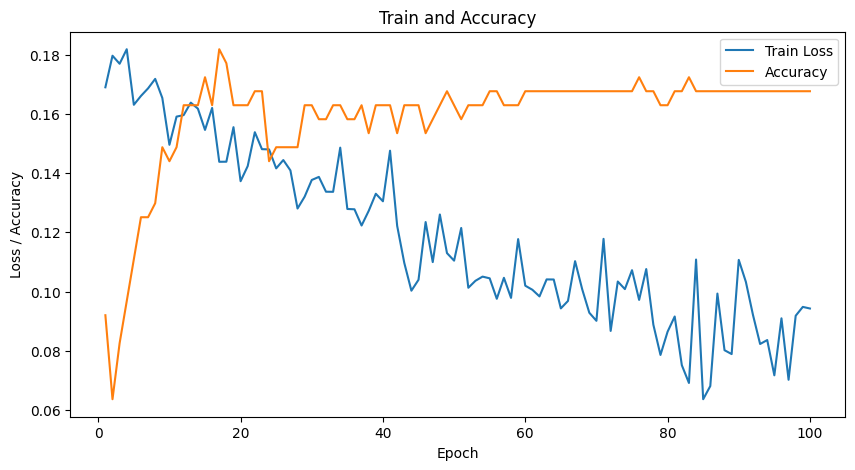

In [9]:
from utils import train_func_classification
model = TextCNN(768, 2)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
_, checkpoints, _, _ = train_func_classification(model, nn.CrossEntropyLoss(), optimizer, sst2_embed_train_dataloader, sst2_embed_validate_dataloader, 100)

In [10]:
checkpoints = ['../checkpoint/TextCNN/TextCNN_epoch_10_0.1.pth',
 '../checkpoint/TextCNN/TextCNN_epoch_20_0.2.pth',
 '../checkpoint/TextCNN/TextCNN_epoch_40_0.4.pth',
 '../checkpoint/TextCNN/TextCNN_epoch_60_0.6.pth',
 '../checkpoint/TextCNN/TextCNN_epoch_80_0.8.pth',
 '../checkpoint/TextCNN/TextCNN_epoch_100_1.0.pth']

In [11]:
import os
import sys
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)
from torch_influence.base import BaseObjective
from torch_influence.modules import CGInfluenceModule, LiSSAInfluenceModule, AutogradInfluenceModule
from torch.utils.data import DataLoader
from matplotlib import pyplot as plt
import numpy as np

def save_checkpoint(model, optimizer, epoch, sum_epochs, filepath="../checkpoint"):
    completion_rate = epoch / sum_epochs
    checkpoint = {
        'epoch': epoch,
        'degree of completion': completion_rate,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
    }
    filename = f"{filepath}/{type(model).__name__}_epoch_{epoch}_{completion_rate}.pth"
    torch.save(checkpoint, filename)
    print(f"Checkpoint at {completion_rate} saved: {filename}")
    return filename
    
def load_checkpoint(model, optimizer, filepath, device='cpu'):
    checkpoint = torch.load(filepath, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    epoch = checkpoint['epoch']
    completion_rate = checkpoint['degree of completion']
    print(f"Checkpoint loaded at epoch {epoch} with completion rate {completion_rate}")
    return model, optimizer, epoch, completion_rate


def train_func_classification(model, criterion, optimizer, train_loader, validation_loader, epochs):
    train_losses = []
    accuracies = []
    checkpoints = []
    
    for epoch in range(epochs):
        model.train()
        loss = 0.0
        for x_batch, y_batch in train_loader:
            optimizer.zero_grad()
            y_pred = model(x_batch)
            loss = criterion(y_pred, y_batch)
            loss.backward()
            optimizer.step()
            loss += loss.item()
            
        loss = loss / len(train_loader)
        train_losses.append(loss)
            
        model.eval()
        correct_count = 0
        for x_val_batch, y_val_batch in validation_loader:
            y_pred = model(x_val_batch)
            predictions = torch.argmax(y_pred, dim=-1)
            result = predictions == y_val_batch
            correct_count += result.sum()
            
        accuracy = (correct_count / len(validation_loader.dataset)).item()
        accuracies.append(accuracy)
        print(f"Epoch: {epoch + 1}, Train Loss: {loss}, accuracy: {accuracy}")
        if (epoch + 1) / epochs in [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]:
            checkpoint_f = save_checkpoint(model, optimizer, epoch + 1, epochs, f"../checkpoint/{type(model).__name__}")
            checkpoints.append(checkpoint_f)
        
    epochs_range = range(1, epochs + 1)
    plt.figure(figsize=(10, 5))
    train_losses = [loss.detach().numpy() for loss in train_losses]
    max_accuracy = np.max(accuracies)
    min_accuracy = np.min(accuracies)
    accuracy_diff = max_accuracy - min_accuracy
    val_accuracies = [((accuracy - min_accuracy) / accuracy_diff) * (np.max(train_losses) - np.min(train_losses)) + np.min(train_losses) 
                      for accuracy in accuracies]
    plt.plot(epochs_range, train_losses, label='Train Loss')
    plt.plot(epochs_range, val_accuracies, label='Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Loss / Accuracy')
    plt.title('Train and Accuracy')
    plt.legend()
    plt.show()
    return model, checkpoints, train_losses, accuracies

def calculate_influence_score_nn(
    traindata: DataLoader, 
    testdata: DataLoader, 
    model, 
    criterion,
    device,
    epochs=-1,
    train_func=None,
    per_point=-1, 
    appro="cg"
    ):
    """
    Calculate influence score for each training data point
    Parameters
    ----------
    traindata: train data loader
    testdata: test data loader
    model: nn.Module
    per_point: if >= 0: return instance score for specific test point; else return instance score for test sets
    Returns
    -------

    """

    # initialize the model and optimizer
    trainidx = len(traindata.dataset)
    testidx = len(testdata.dataset)

    class NNObjective(BaseObjective):
        
        # batch: Dataset
        def train_outputs(self, model, batch):
            inputs, _ = batch
            inputs = inputs
            inputs = inputs.to(device, dtype=torch.float)
            return model(inputs)

        def train_loss_on_outputs(self, outputs, batch):
            _, labels = batch
            labels = labels
            labels = labels.to(device)
            return criterion(outputs, labels)

        def train_regularization(self, params):
            return 0

        # training loss by default taken to be
        # train_loss_on_outputs + train_regularization

        def test_loss(self, model, params, batch):
            inputs, labels = batch
            inputs = inputs.to(device, dtype=torch.float)
            labels = labels.to(device)
            return criterion(model(inputs), labels)
        
    if train_func != None:
        model, _, val_losses = train_func(
            model = model,
            criterion = criterion,
            optimizer = torch.optim.Adam(model.parameters(), lr=0.0001),
            train_loader = traindata,
            validation_loader = testdata,
            epochs = epochs,
            )
    
    print("Start calculating influence scores...")

    if appro == "lissa":
        print("LissaInfluenceModule")
        module = LiSSAInfluenceModule(
            model=model,
            objective=NNObjective(),
            train_loader=traindata,
            test_loader=testdata,
            device=device,
            damp=0.003,
            repeat=1,
            depth=2500,
            scale=1e4,
        )
    elif appro == "cg":
        print("CGInfluenceModule")
        module = CGInfluenceModule(
            model=model,
            objective=NNObjective(),
            train_loader=traindata,
            test_loader=testdata,
            device=device,
            damp=0.003,
            atol=1e-8,
            maxiter=1000,
        )
    elif appro == "autograd":
        print("AutogradInfluenceModule")
        module = AutogradInfluenceModule(
            model=model,
            objective=NNObjective(),
            train_loader=traindata,
            test_loader=testdata,
            device=device,
            damp=0.003
        )

    print(f"train data size: {len(traindata.dataset)}")
    print(f"test data size: {len(testdata.dataset)}")
    if train_func != None:
        print(f"model performance validation loss / accuracy: {val_losses[-1]}")
    
    if per_point >= 0:
        scores = module.influences(np.arange(trainidx),  np.array([per_point])).cpu().numpy().reshape(-1)
    else:
        scores = module.influences(np.arange(trainidx), np.arange(testidx)).cpu().numpy().reshape(-1)
    return scores

def influence_at_checkpoints(traindata, testdata, model, optimizer,
                             criterion, checkpoints, device, per_point=-1, appro="cg"):
    scores = []
    for checkpoint in tqdm(checkpoints, desc=f"Calculating influence scores"):
        model, optimizer, _, completion_rate = load_checkpoint(model, optimizer, checkpoint)
        print(f"completion_rate: {completion_rate}" )
        score = calculate_influence_score_nn(traindata, testdata, model, criterion, device, per_point=per_point, appro=appro)
        scores.append(score)
    return scores

In [14]:
model = TextCNN(768, 2)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
sst2_influences = influence_at_checkpoints(sst2_embed_train_dataloader, sst2_embed_validate_dataloader, model, optimizer,
                                           nn.CrossEntropyLoss(), checkpoints, "cpu", appro="lissa")

Calculating influence scores:   0%|          | 0/6 [00:00<?, ?it/s]C:\Users\yyxxc\AppData\Local\Temp\ipykernel_30424\3943877874.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  embedding = torch.tensor(self.embeddings[idx])


Checkpoint loaded at epoch 10 with completion rate 0.1
completion_rate: 0.1
Start calculating influence scores...
LissaInfluenceModule
train data size: 500
test data size: 80
Calculating stest...


Calculating influence scores:  17%|█▋        | 1/6 [07:51<39:16, 471.29s/it]

Checkpoint loaded at epoch 20 with completion rate 0.2
completion_rate: 0.2
Start calculating influence scores...
LissaInfluenceModule
train data size: 500
test data size: 80
Calculating stest...


Calculating influence scores:  33%|███▎      | 2/6 [15:38<31:15, 468.98s/it]

...

Calculating influence scores:  67%|██████▋   | 4/6 [31:17<15:38, 469.09s/it]

Checkpoint loaded at epoch 80 with completion rate 0.8
completion_rate: 0.8
Start calculating influence scores...
LissaInfluenceModule
train data size: 500
test data size: 80
Calculating stest...


Calculating influence scores:  83%|████████▎ | 5/6 [39:09<07:50, 470.40s/it]

Checkpoint loaded at epoch 100 with completion rate 1.0
completion_rate: 1.0
Start calculating influence scores...
LissaInfluenceModule
train data size: 500
test data size: 80
Calculating stest...


Calculating influence scores: 100%|██████████| 6/6 [50:30<00:00, 505.08s/it]


In [65]:
def top_n_influences(ckpt_influences, train_embeds, num_per_row=10):
    top_inf_texts = []
    for ckpt, influences in enumerate(ckpt_influences):
        sorted_influences = torch.argsort(torch.from_numpy(influences), descending=True)
        top_indexes = sorted_influences[:num_per_row]
        top_influential_train_data = np.array([train_embeds[index].detach().numpy() for index in top_indexes])
        top_inf_texts.append(top_influential_train_data)
        
    # [num_checkpoints, num_per_row, batch_size, num_of_tokens, embed_dim]
    top_inf_texts = np.array(top_inf_texts).squeeze(2) # remove batch_size dimension
    return top_inf_texts


top_inf_embeds = top_n_influences(sst2_influences, sst2_train_embeddings, 10)
print(top_inf_embeds.shape)

(6, 10, 78, 768)


checkpoint: 0, shape:(8, 59904)
checkpoint: 1, shape:(8, 59904)
checkpoint: 2, shape:(8, 59904)
checkpoint: 3, shape:(8, 59904)
checkpoint: 4, shape:(8, 59904)
checkpoint: 5, shape:(8, 59904)


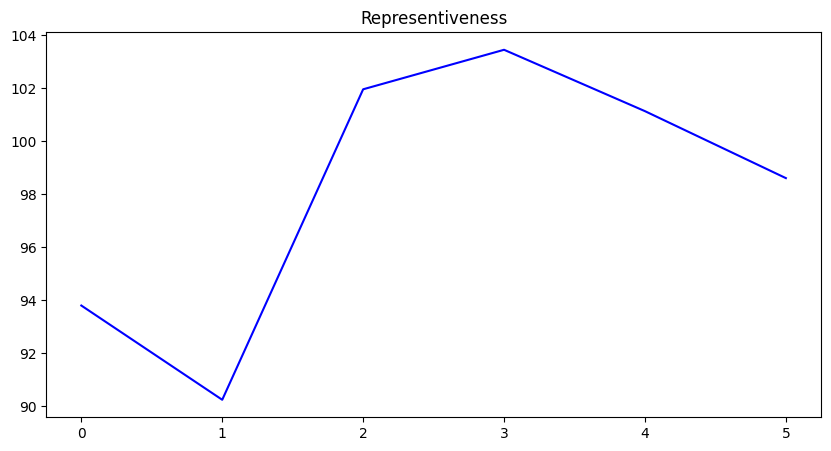

In [ ]:
from sklearn.metrics.pairwise import euclidean_distances

# distance between text embeddings of within a single checkpoint
def calc_representiveness(embeds):
    distances = euclidean_distances(embeds, embeds)
    mean_distance = np.mean(distances)
    return mean_distance

representivenesses = []
for ckpt, ckpt_embeds in enumerate(top_inf_embeds):
    ckpt_embeds = ckpt_embeds.reshape(-1, 78 * 768)
    print(f"checkpoint: {ckpt}, shape:{ckpt_embeds.shape}")
    mean_dist = calc_representiveness(ckpt_embeds)
    representivenesses.append(mean_dist)
plt.subplots(figsize=(10, 5))
plt.title("Representiveness")
plt.plot(representivenesses, label="Representiveness", color='blue')

Text(0, 0.5, 'Entropy')

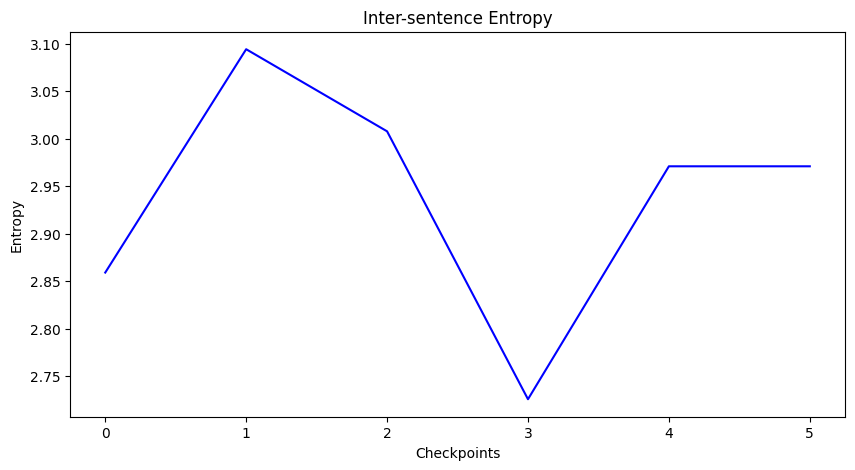

In [95]:
from scipy.spatial.distance import pdist
from scipy.stats import entropy

def inter_sentence_entropy(sentence_embeds):
    pairwise_distances = pdist(sentence_embeds, metric='cosine')
    distance_probs, _ = np.histogram(pairwise_distances, bins=30, density=True)
    distance_probs = distance_probs / np.sum(distance_probs)
    pairwise_entropy = entropy(distance_probs)
    return pairwise_entropy

entropies = []
for ckpt, ckpt_embeds in enumerate(top_inf_embeds):
    ckpt_embeds = np.mean(ckpt_embeds, axis=1)
    batch_entropy = inter_sentence_entropy(ckpt_embeds)
    entropies.append(batch_entropy)
plt.subplots(figsize=(10, 5))
plt.title("Inter-sentence Entropy")
plt.plot(entropies, label="Inter-sentence Entropy", color='blue')
plt.xlabel("Checkpoints")
plt.ylabel("Entropy")

在accuracy趋于稳定的阶段entropy较高

Text(0, 0.5, 'Entropy')

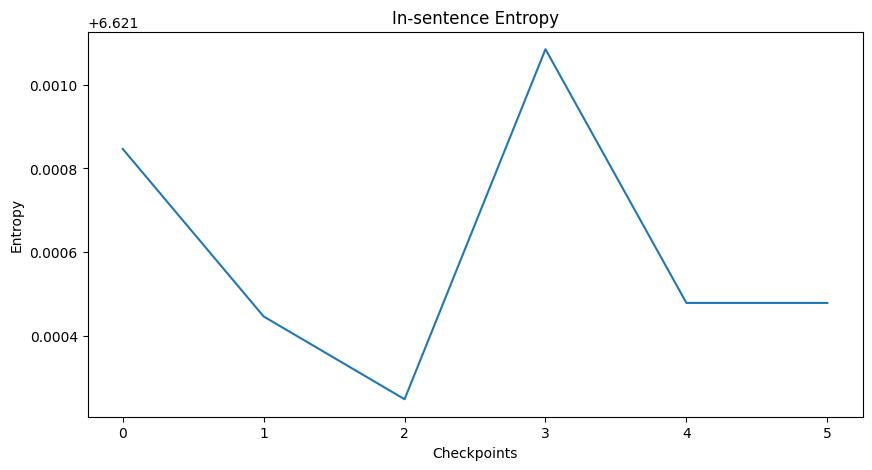

In [81]:
def inner_entropy(sentence_embed):
    mean_embed = np.mean(sentence_embed, axis=0)
    probabilities = torch.nn.functional.softmax(torch.tensor(mean_embed), dim=0).numpy()
    inner_entropy = entropy(probabilities)
    return inner_entropy

entropies = []
for ckpt, ckpt_embeds in enumerate(top_inf_embeds):
    embed_entropies = [inner_entropy(embed) for embed in ckpt_embeds]
    entropies.append(np.mean(embed_entropies))
plt.subplots(figsize=(10, 5))
plt.title("In-sentence Entropy")
plt.plot(entropies, label="In-sentence Entropy")
plt.xlabel("Checkpoints")
plt.ylabel("Entropy")

Text(0, 0.5, 'Volume')

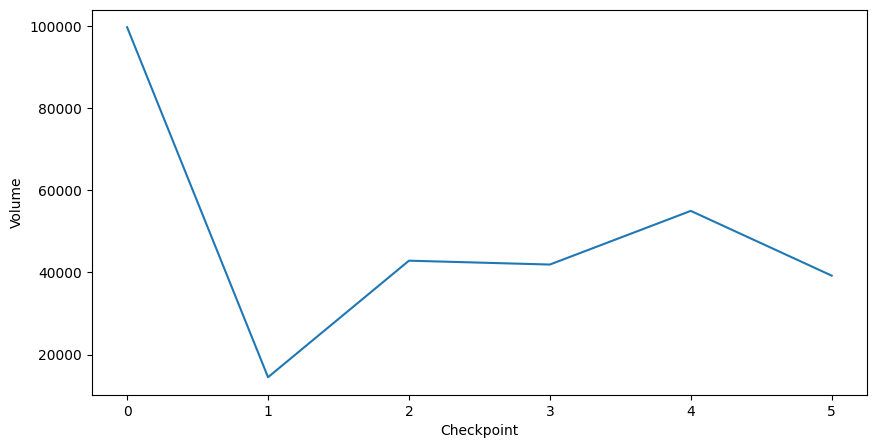

In [94]:
from sklearn.decomposition import PCA

def volume(sentences_embeds):
    return np.sqrt(np.linalg.det(sentences_embeds.T@sentences_embeds))

def pca(x, k):
    x_std = (x - np.mean(x, axis=0)) / (np.std(x, axis=0) + 1e-8)
    pca = PCA(n_components=k)
    pca.fit(x_std)
    return pca.components_

volumes = []
for ckpt_embeds in top_inf_embeds:
    ckpt_embeds = np.mean(ckpt_embeds, axis=1)
    W = pca(ckpt_embeds, 10)
    Z_embeds = ckpt_embeds @ W.T
    volumes.append(volume(Z_embeds))
plt.subplots(figsize=(10, 5))
plt.plot(volumes)
plt.xlabel("Checkpoint")
plt.ylabel("Volume")

Volume decrease then increase again?